In [1]:
import os 
import pickle
import numpy as np
from tqdm.notebook import tqdm
import tensorflow as tf
from tensorflow.keras.applications import Xception
from keras.applications.xception import preprocess_input
from tensorflow.keras.preprocessing.image import load_img,img_to_array
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.utils import to_categorical ,plot_model
from tensorflow.keras.layers import Input ,Dense ,LSTM ,Embedding ,Dropout ,add

2024-03-17 01:26:47.515812: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-03-17 01:26:47.515919: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-03-17 01:26:47.637369: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
MAIN_DIR ='/kaggle/input/flickr30k/'
OUTPUT_DIR = '/kaggle/working'

In [3]:
#load Xception model 
xception= Xception()
model = Model(inputs=xception.inputs,outputs=xception.layers[-2].output)
print(model.summary())

91884032/91884032 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 299, 299,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 149, 149,  │        864 │ input_layer[0][0] │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_bn     │ (None, 149, 149,  │        128 │ block1_conv1[0][… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_act    │ (None, 149, 149,  │          0 │ block1_conv1_bn[… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 147, 147,  │     18,432 │ block1_conv1_act… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_bn     │ (None, 147, 147,  │        256 │ block1_conv2[0][… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_act    │ (None, 147, 147,  │          0 │ block1_conv2_bn[… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1     │ (None, 147, 147,  │      8,768 │ block1_conv2_act… │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1_bn  │ (None, 147, 147,  │        512 │ block2_sepconv1[… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_act │ (None, 147, 147,  │          0 │ block2_sepconv1_… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2     │ (None, 147, 147,  │     17,536 │ block2_sepconv2_… │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_bn  │ (None, 147, 147,  │        512 │ block2_sepconv2[… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 74, 74,    │      8,192 │ block1_conv2_act… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 74, 74,    │          0 │ block2_sepconv2_… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 74, 74,    │        512 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 74, 74,    │          0 │ block2_pool[0][0… │
│                     │ 128)              │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_sepconv1_act │ (None, 74, 74,    │          0 │ add[0][0]       

 Total params: 20,861,480 (79.58 MB)

 Trainable params: 20,806,952 (79.37 MB)

 Non-trainable params: 54,528 (213.00 KB)

None


In [ ]:
feature_image ={}
dir_img = os.path.join(MAIN_DIR ,'flickr30k_images')

for img_name in tqdm(os.listdir(dir_img)):
    img_path = dir_img +'/'+ img_name
    image = load_img(img_path,target_size=(299,299))
    img_array = img_to_array(image)
    img_reshape = img_array.reshape((1,img_array.shape[0],img_array.shape[1],img_array.shape[2]))
    img_pre = preprocess_input(img_reshape)
    feature = model.predict(img_pre ,verbose=0)
    img_id= img_name.split('.')[0]
    feature_image[img_id]= feature

  0%|          | 0/31783 [00:00<?, ?it/s]

I0000 00:00:1710564696.125881     114 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


In [20]:
pickle.dump(feature_image,open(os.path.join(OUTPUT_DIR,'Feature_image.pkl'),'wb'))

In [3]:
with open(os.path.join('/kaggle/input/image-caption-model/model/Feature_image.pkl'), 'rb') as f:
    feature_image = pickle.load(f)

In [4]:
#load caption
with open(os.path.join(MAIN_DIR,'captions.txt'),'r') as c:
    next(c)
    captions = c.read()

In [5]:
captions[:100]

'1000092795.jpg,0,Two young guys with shaggy hair look at their hands while hanging out in the yard .'

In [6]:
captions_img={}

for line in tqdm(captions.split('\n')):
    token = line.split(',')
    if len(line)<2:
        continue
    img_id,caption = token[0],token[2]
    img_id = img_id.split('.')[0]
    caption = ''.join(caption)
    if img_id not in captions_img:
        captions_img[img_id]=[]
    captions_img[img_id].append(caption)

  0%|          | 0/158916 [00:00<?, ?it/s]

In [7]:
len(captions_img)

31783

In [8]:
def clean(captions_img):
    for key, captions in captions_img.items():
        for i in range(len(captions)):
            caption = captions[i]
            caption = caption.lower()
            caption = caption.replace('[^A-Za-Z]','')
            caption = caption.replace('\s+',' ')
            caption = 'startseq '+ ' '.join([word for word in caption.split()if len(word)>1]) +' endseq'
            captions[i] = caption

In [9]:
captions_img['1000092795']

['Two young guys with shaggy hair look at their hands while hanging out in the yard .',
 'Two young  White males are outside near many bushes .',
 'Two men in green shirts are standing in a yard .',
 'A man in a blue shirt standing in a garden .',
 'Two friends enjoy time spent together .']

In [10]:
clean(captions_img)

In [11]:
captions_img['1000092795']

['startseq two young guys with shaggy hair look at their hands while hanging out in the yard endseq',
 'startseq two young white males are outside near many bushes endseq',
 'startseq two men in green shirts are standing in yard endseq',
 'startseq man in blue shirt standing in garden endseq',
 'startseq two friends enjoy time spent together endseq']

In [12]:
all_captions = []
for key in captions_img:
    for caption in captions_img[key]:
        all_captions.append(caption)

In [13]:
len(all_captions)

158915

In [14]:
all_captions[:10]

['startseq two young guys with shaggy hair look at their hands while hanging out in the yard endseq',
 'startseq two young white males are outside near many bushes endseq',
 'startseq two men in green shirts are standing in yard endseq',
 'startseq man in blue shirt standing in garden endseq',
 'startseq two friends enjoy time spent together endseq',
 'startseq several men in hard hats are operating giant pulley system endseq',
 'startseq workers look down from up above on piece of equipment endseq',
 'startseq two men working on machine wearing hard hats endseq',
 'startseq four men on top of tall structure endseq',
 'startseq three men on large rig endseq']

In [15]:
# Preprocessing Text

tokenizer = Tokenizer()
tokenizer.fit_on_texts(all_captions)
vcab_size = len(tokenizer.word_index)+1

In [16]:
vcab_size

18319

In [17]:
# get max len of caption 

max_length = max(len(caption.split()) for caption in all_captions)
max_length

74

In [18]:
# train test split

image_ids = list(captions_img.keys())
split = int(len(image_ids)*0.8)
split

25426

In [19]:
train = image_ids[ : split]
test = image_ids[split : ]

In [20]:
def data_generator(data_keys, captions_img, feature, tokenizer, max_length, vcab_size, batch_size):
    X1, X2, y = list(), list(), list()
    batch = 0
    while 1:
        for key in data_keys:
            batch += 1
            captions = captions_img[key]
            for caption in captions:
                #encode the sequence
                seq = tokenizer.texts_to_sequences([caption])[0]
                #split the seq to X , y pairs
                for i in range(1 , len(seq)):
                    in_seq , out_seq = seq[:i],seq[i]
                    # padding in_seq
                    in_seq = pad_sequences([in_seq],maxlen=max_length)[0]
                    # encode out_seq
                    out_seq = to_categorical([out_seq], num_classes = vcab_size)[0]
                    #store seqs
                    X1.append(feature_image[key][0])
                    X2.append(in_seq)
                    y.append(out_seq)
            if batch == batch_size :
                X1, X2, y = np.array(X1), np.array(X2), np.array(y)
                yield (X1, X2), y
                X1, X2, y = list(), list(), list()
                batch = 0
                
    

## **Model**

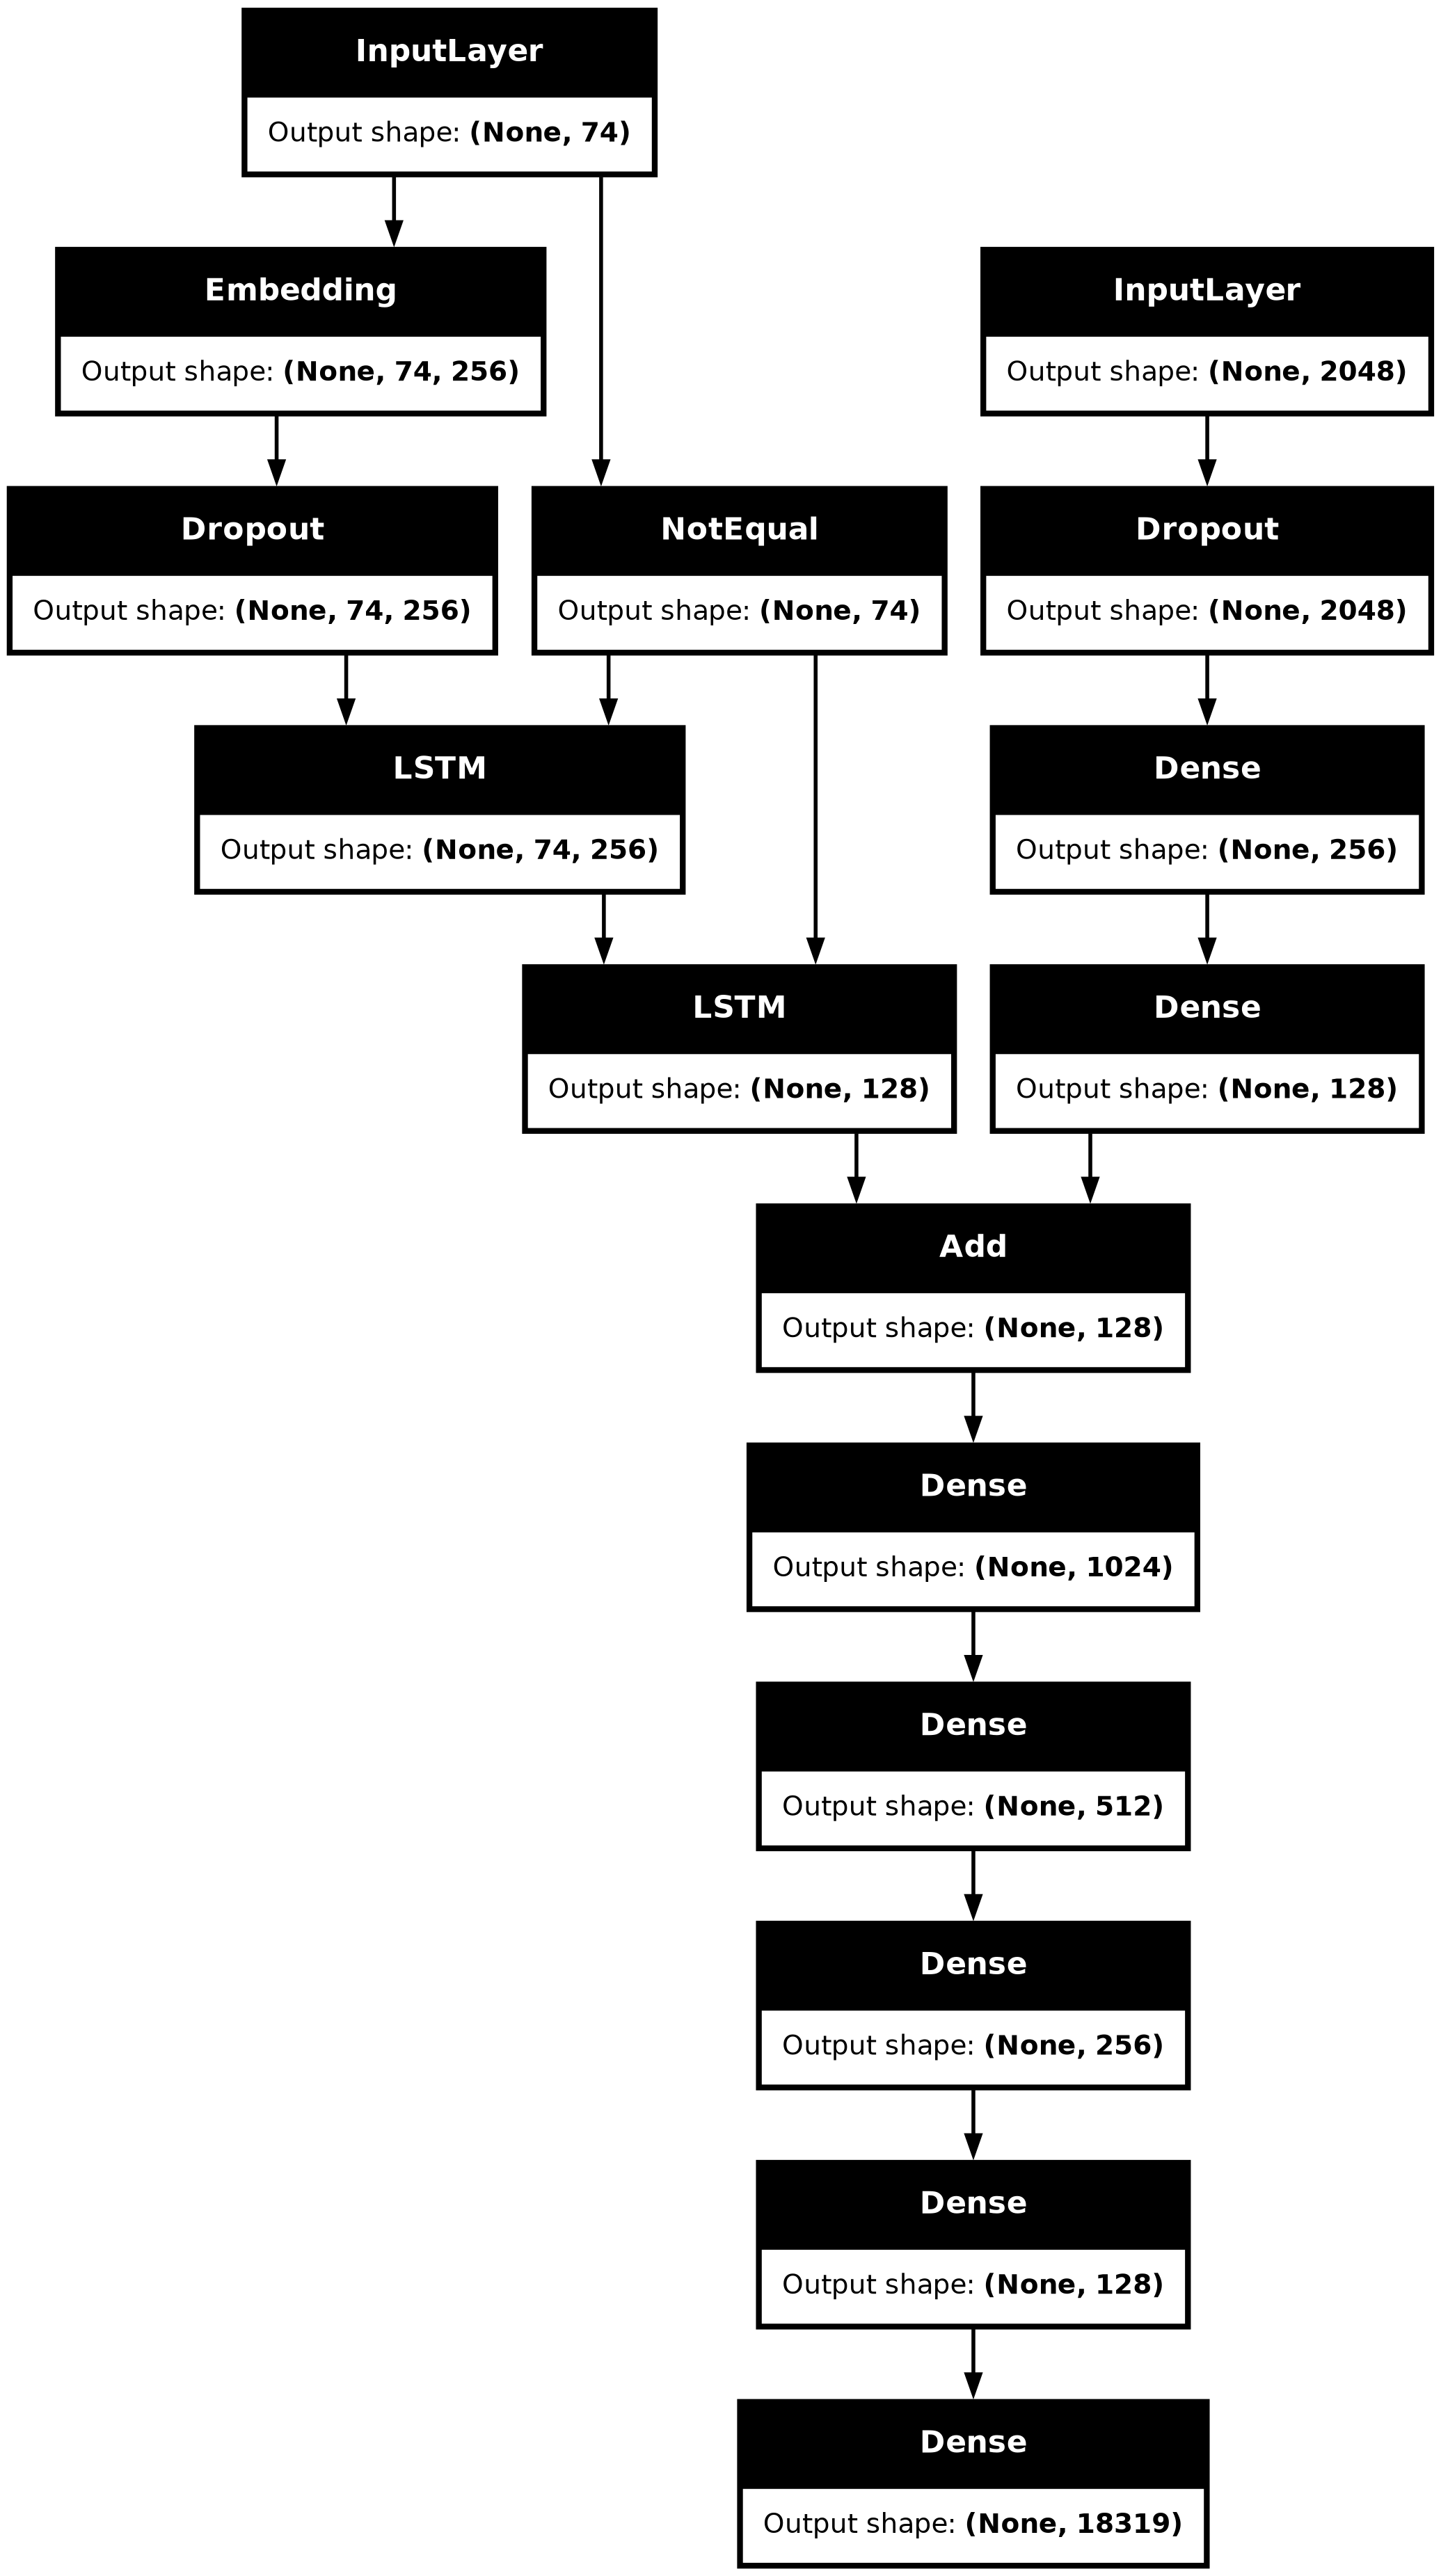

In [23]:
# Imgae model
inputs1 = Input(shape=(2048,))
fe1 = Dropout(0.3)(inputs1)
fe2 = Dense(256, activation='relu')(fe1)
fe3 = Dense(128, activation='relu')(fe2)


# Seq model 
inputs2 = Input(shape=(max_length,))
se1 = Embedding(vcab_size, 256 , mask_zero = True)(inputs2)
se2 = Dropout(0.3)(se1)
se3 = LSTM(256, return_sequences=True)(se2)
se4 = LSTM(128)(se3)


# Concate two model 
model = add([fe3 , se4])
model = Dense(1024, activation ='relu')(model)
model = Dense(512, activation ='relu')(model)
model = Dense(256, activation ='relu')(model)
model = Dense(128, activation ='relu')(model)
outputs = Dense(vcab_size, activation ='softmax')(model)

model = Model(inputs =[inputs1 , inputs2], outputs =outputs)
model.compile(loss ='categorical_crossentropy', optimizer ='adam', metrics=['accuracy'])

# plot model
plot_model(model,show_shapes= True)

In [24]:
# Train the New Model  
epochs = 25
batch_size = 32
steps = len(train)//batch_size

for i in range(epochs):
    generator = data_generator(train ,captions_img ,feature_image ,tokenizer ,max_length ,vcab_size ,batch_size)
    # fit
    print(f'EPOCH {i + 1} :')
    model.fit(generator,epochs=1,steps_per_epoch=steps,verbose=1)

EPOCH 1 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 422s 522ms/step - accuracy: 0.1325 - loss: 5.7806
EPOCH 2 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 413s 520ms/step - accuracy: 0.2478 - loss: 4.3101
EPOCH 3 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 412s 519ms/step - accuracy: 0.2747 - loss: 3.9445
EPOCH 4 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 413s 520ms/step - accuracy: 0.2925 - loss: 3.7172
EPOCH 5 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 413s 520ms/step - accuracy: 0.3047 - loss: 3.5631
EPOCH 6 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 413s 520ms/step - accuracy: 0.3143 - loss: 3.4462
EPOCH 7 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 414s 521ms/step - accuracy: 0.3214 - loss: 3.3534
EPOCH 8 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 413s 520ms/step - accuracy: 0.3280 - loss: 3.2779
EPOCH 9 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 414s 521ms/step - accuracy: 0.3343 - loss: 3.2127
EPOCH 10 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 416s 523ms/step - accuracy: 0.3398 - loss: 3.1562
EPOCH 11 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 414s 521ms/step - accuracy: 0.3447 - loss: 3.1070
EPOCH 12 :
794/794 

In [37]:
# Train the New Model 
epochs = 10
batch_size = 32
steps = len(train)//batch_size

for i in range(epochs):
    generator = data_generator(train ,captions_img ,feature_image ,tokenizer ,max_length ,vcab_size ,batch_size)
    # fit
    print(f'EPOCH {i + 1} :')
    model.fit(generator,epochs=1,steps_per_epoch=steps,verbose=1)

EPOCH 1 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 415s 523ms/step - accuracy: 0.3911 - loss: 2.7139
EPOCH 2 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 416s 524ms/step - accuracy: 0.3927 - loss: 2.7002
EPOCH 3 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 416s 523ms/step - accuracy: 0.3949 - loss: 2.6855
EPOCH 4 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 416s 524ms/step - accuracy: 0.3965 - loss: 2.6725
EPOCH 5 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 418s 526ms/step - accuracy: 0.3983 - loss: 2.6604
EPOCH 6 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 416s 524ms/step - accuracy: 0.3993 - loss: 2.6492
EPOCH 7 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 417s 525ms/step - accuracy: 0.4012 - loss: 2.6365
EPOCH 8 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 416s 524ms/step - accuracy: 0.4021 - loss: 2.6285
EPOCH 9 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 419s 528ms/step - accuracy: 0.4039 - loss: 2.6158
EPOCH 10 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 417s 525ms/step - accuracy: 0.4048 - loss: 2.6067


In [25]:
# Train the model 
epochs = 25
batch_size = 32
steps = len(train)//batch_size

for i in range(epochs):
    generator = data_generator(train ,captions_img ,feature_image ,tokenizer ,max_length ,vcab_size ,batch_size)
    # fit
    print(f'EPOCH {i} :')
    model.fit(generator,epochs=1,steps_per_epoch=steps,verbose=1)

EPOCH 0 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 384s 478ms/step - accuracy: 0.1667 - loss: 5.4562
EPOCH 1 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 383s 482ms/step - accuracy: 0.2843 - loss: 3.8413
EPOCH 2 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 378s 475ms/step - accuracy: 0.3087 - loss: 3.5054
EPOCH 3 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 377s 475ms/step - accuracy: 0.3241 - loss: 3.2999
EPOCH 4 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 385s 485ms/step - accuracy: 0.3356 - loss: 3.1477
EPOCH 5 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 383s 482ms/step - accuracy: 0.3470 - loss: 3.0269
EPOCH 6 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 379s 477ms/step - accuracy: 0.3581 - loss: 2.9319
EPOCH 7 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 377s 474ms/step - accuracy: 0.3670 - loss: 2.8574
EPOCH 8 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 373s 469ms/step - accuracy: 0.3738 - loss: 2.7979
EPOCH 9 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 371s 467ms/step - accuracy: 0.3799 - loss: 2.7481
EPOCH 10 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 379s 477ms/step - accuracy: 0.3854 - loss: 2.7043
EPOCH 11 :
794/794 ━

In [ ]:
# Train the model 
epochs = 20
batch_size = 32
steps = len(train)//batch_size

for i in range(epochs):
    generator = data_generator(train ,captions_img ,feature_image ,tokenizer ,max_length ,vcab_size ,batch_size)
    # fit
    print(f'EPOCH {i+1} :')
    model.fit(generator,epochs=1,steps_per_epoch=steps,verbose=1)

EPOCH 1 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 385s 485ms/step - accuracy: 0.4284 - loss: 2.3995
EPOCH 2 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 387s 487ms/step - accuracy: 0.4292 - loss: 2.3900
EPOCH 3 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 385s 484ms/step - accuracy: 0.4308 - loss: 2.3796
EPOCH 4 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 385s 484ms/step - accuracy: 0.4319 - loss: 2.3718
EPOCH 5 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 388s 488ms/step - accuracy: 0.4328 - loss: 2.3616
EPOCH 6 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 387s 488ms/step - accuracy: 0.4345 - loss: 2.3536
EPOCH 7 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 386s 486ms/step - accuracy: 0.4351 - loss: 2.3471
EPOCH 8 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 384s 483ms/step - accuracy: 0.4368 - loss: 2.3396
EPOCH 9 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 384s 484ms/step - accuracy: 0.4376 - loss: 2.3341
EPOCH 10 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 382s 481ms/step - accuracy: 0.4386 - loss: 2.3258
EPOCH 11 :
794/794 ━━━━━━━━━━━━━━━━━━━━ 384s 483ms/step - accuracy: 0.4404 - loss: 2.3182
EPOCH 12 :
794/794 

## **Saving Model**

In [25]:
# Save model architecture as JSON
model_json = model.to_json()
with open("modelN.json", "w") as json_file:
    json_file.write(model_json)


In [26]:
# Save model weights
model.save_weights("Nmodel_weights.weights.h5")

In [32]:
# Save tokenizer configuration
with open('tokenizer.pickle', 'wb') as handle:
    pickle.dump(tokenizer, handle, protocol=pickle.HIGHEST_PROTOCOL)


In [33]:
vocab_size = len(tokenizer.word_index) + 1
with open('vocab_size.txt', 'w') as f:
    f.write(str(vocab_size))


In [27]:
embedding_matrix = model.layers[2].get_weights()[0]  # Assuming embedding layer is the second layer
np.save('Nembedding_matrix.npy', embedding_matrix)


In [28]:
model.save('Image Caption GeneratorN.h5')

## **Prediction**

In [29]:
def idx_to_word(num, tokenizer):
    for word, index in tokenizer.word_index.items():
        if index == num:
            return word
    return None

In [30]:
def predict_caption(model, image, tokenizer, max_length):
    in_text = 'startseq'
    for i in range(max_length):
        # encode input sequence
        sequence = tokenizer.texts_to_sequences([in_text])[0]
        # pad the sequence
        sequence = pad_sequences([sequence], max_length)
        # predict next word
        yhat = model.predict([image, sequence], verbose=0)
        yhat = np.argmax(yhat)
        word = idx_to_word(yhat, tokenizer)
        if word is None:
            break
        in_text += " " + word
        if word == 'endseq':
            break
      
    return in_text

In [31]:
from nltk.translate.bleu_score import corpus_bleu

actual, predicted = list(), list()

for key in tqdm(test[:1000]):
    captions = captions_img[key]
    y_pred = predict_caption(model, feature_image[key], tokenizer, max_length) 
    actual_captions = [caption.split() for caption in captions]
    y_pred = y_pred.split()
    actual.append(actual_captions)
    predicted.append(y_pred)
    
# calcuate BLEU score
print("BLEU-1: %f" % corpus_bleu(actual, predicted, weights=(1.0, 0, 0, 0)))
print("BLEU-2: %f" % corpus_bleu(actual, predicted, weights=(0.5, 0.5, 0, 0)))

  0%|          | 0/1000 [00:00<?, ?it/s]

BLEU-1: 0.574258
BLEU-2: 0.328862


In [36]:
from nltk.translate.bleu_score import corpus_bleu

actual, predicted = list(), list()

for key in tqdm(test[:1000]):
    captions = captions_img[key]
    y_pred = predict_caption(model, feature_image[key], tokenizer, max_length) 
    actual_captions = [caption.split() for caption in captions]
    y_pred = y_pred.split()
    actual.append(actual_captions)
    predicted.append(y_pred)
    
# calcuate BLEU score
print("BLEU-1: %f" % corpus_bleu(actual, predicted, weights=(1.0, 0, 0, 0)))
print("BLEU-2: %f" % corpus_bleu(actual, predicted, weights=(0.5, 0.5, 0, 0)))

  0%|          | 0/1000 [00:00<?, ?it/s]

BLEU-1: 0.582299
BLEU-2: 0.338033


In [35]:
from PIL import Image
import matplotlib.pyplot as plt
def generate_caption(image_name):
    image_id = image_name.split('.')[0]
    img_path = os.path.join(MAIN_DIR, "flickr30k_images", image_name)
    image = Image.open(img_path)
    captions = captions_img[image_id]
    print('---------------------Actual---------------------')
    for caption in captions:
        print(caption)
    y_pred = predict_caption(model, feature_image[image_id], tokenizer, max_length)
    print('--------------------Predicted--------------------')
    print(y_pred)
    plt.axis('off')
    plt.imshow(image)

---------------------Actual---------------------
startseq group of people are wearing signs that say on strike while someone is speaking at booth with the presidential seal endseq
startseq strike is currently going on and there are lots of people endseq
startseq person speaks at protest on college campus endseq
startseq woman is speaking at podium outdoors endseq
startseq members of strike at yale university endseq
--------------------Predicted--------------------
startseq crowd of people are walking down street endseq


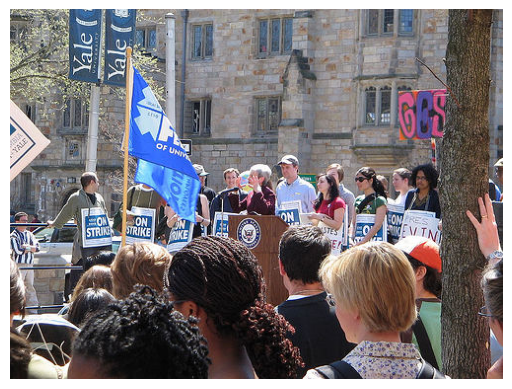

In [49]:
generate_caption(f'{test[-10]}.jpg')

---------------------Actual---------------------
startseq three people is just sitting in the park one is lying on the grass the other one is looking around and the other one is taking photos endseq
startseq girl is taking photograph on nice lawn while others lounge next to her endseq
startseq blond girl in white shirt and black pants is looking through her camera endseq
startseq two girls are sitting on the grass as one is taking picture endseq
startseq seated woman in white shirt is taking photo endseq
--------------------Predicted--------------------
startseq man in blue shirt and woman in black and white shirt are sitting on blanket in the grass endseq


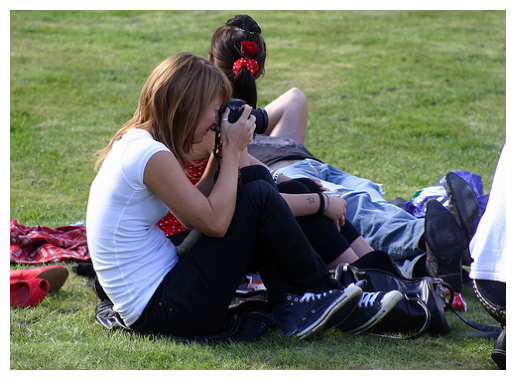

In [51]:
generate_caption(f'{test[74]}.jpg')

---------------------Actual---------------------
startseq man in shorts and hawaiian shirt leans over the rail of pilot boat with fog and mountains in the background endseq
startseq young man hanging over the side of boat which is in like with fog rolling over hill behind it endseq
startseq man is leaning off of the side of blue and white boat as it sits in body of water endseq
startseq man riding small boat in harbor with fog and mountains in the background endseq
startseq man on moored blue and white boat with hills and mist in the background endseq
--------------------Predicted--------------------
startseq man is standing on dock with fishing nets endseq


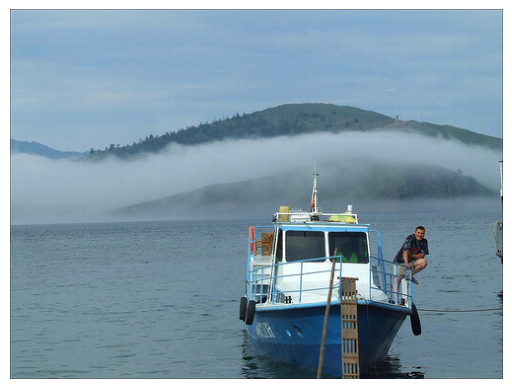

In [48]:
generate_caption(f'{test[-1]}.jpg')

---------------------Actual---------------------
startseq woman of perhaps asian descent is sitting at table surrounded by several dishes endseq
startseq woman in sunglasses making pouting face while eating seafood endseq
startseq young girl in sunglasses eating at restaurant endseq
startseq woman making grumpy face while eating seafood endseq
startseq girl making faces while eating at restaurant endseq
--------------------Predicted--------------------
startseq woman in black shirt is eating endseq


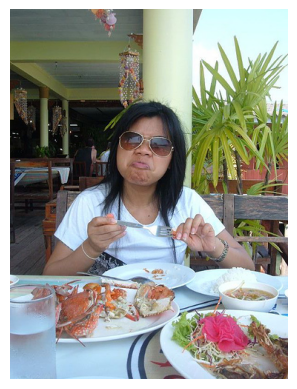

In [45]:
generate_caption(f'{test[2022]}.jpg')

---------------------Actual---------------------
startseq young black man sits in unfinished brick and mortar building the large window to his left has no glass it is daytime and the sun drenches the room he sits at simple bench and desk holding two blue pens and reading from one of the two note books that lay on the desk he wears yellow polo and lights blue shorts endseq
startseq young african man holding pen in each hand studying book while sitting near an open window endseq
startseq young black man writes in notebook on desk near window inside concrete building endseq
startseq student sitting in simple classroom appears deep in thought endseq
startseq young student is studying in quiet outdoor setting endseq
--------------------Predicted--------------------
startseq man in blue shirt is sitting on stool endseq


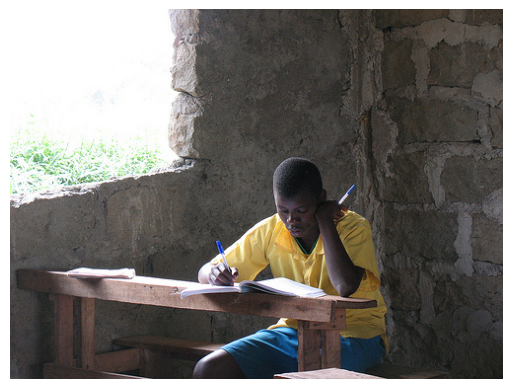

In [43]:
generate_caption(f'{test[1113]}.jpg')

---------------------Actual---------------------
startseq man in blue shirt walks bull with rope wrapped around its horns endseq
startseq the big white cow is decorated with red ball of yarn endseq
startseq older man leading white cow down crowded street endseq
startseq man is leading white bull down the street endseq
startseq an old man leading white cow by rope endseq
--------------------Predicted--------------------
startseq man in blue shirt is standing in front of crowd of people endseq


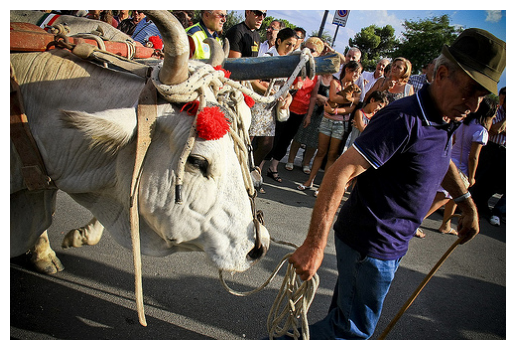

In [41]:
generate_caption(f'{test[111]}.jpg')

---------------------Actual---------------------
startseq man in white shirt playing white guitar standing in front of microphone with the light casting somewhat reddish hue on his shirt endseq
startseq man playing guitar in the fog around other musical instruments on stage endseq
startseq middle-aged guitar player is on stage playing white electric guitar endseq
startseq guy wearing white shirt is playing white guitar endseq
startseq man in dimly lit room playing guitar endseq
--------------------Predicted--------------------
startseq man in black shirt plays guitar endseq


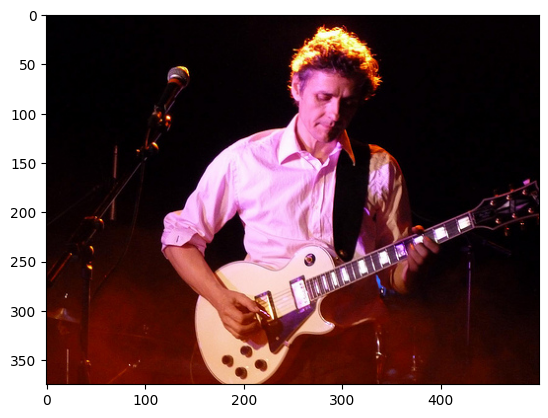

In [54]:
generate_caption(f'{test[1101]}.jpg')

---------------------Actual---------------------
startseq man sits at computer with two monitors appearing to work endseq
startseq young man using an apple computer surfing the internet endseq
startseq man in an orange shirt is using mac computer endseq
startseq man in an office working on the computer endseq
startseq person is sitting in front of computer endseq
--------------------Predicted--------------------
startseq man in black shirt is sitting at desk with computer endseq


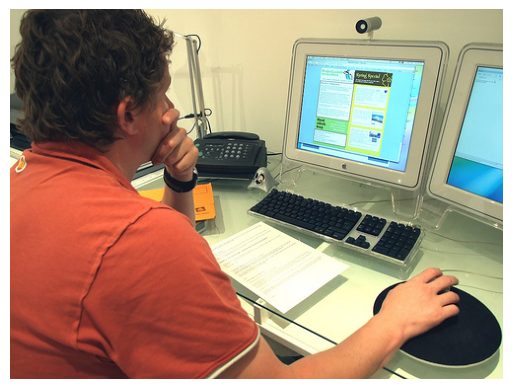

In [56]:
generate_caption(f'{test[740]}.jpg')

---------------------Actual---------------------
startseq three farmers stacking bails of hay on truck endseq
startseq men working in the harvesting the fields endseq
startseq some men are mowing hay in field endseq
startseq farmers cutting and collecting hay endseq
startseq three men are bailing hay endseq
--------------------Predicted--------------------
startseq man in blue shirt is standing in field with bale of hay in front of him endseq


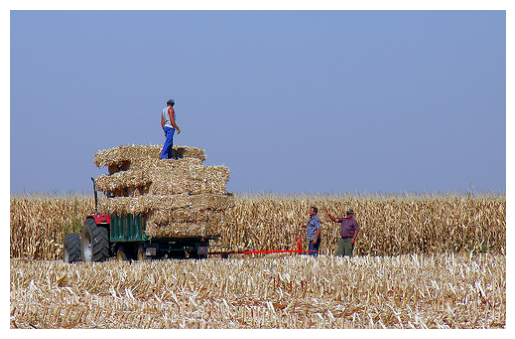

In [57]:
generate_caption(f'{test[720]}.jpg')